# Phase 4a — Gemma Hypothesis Tests + Classifier

Cross-model validation analysis for **Gemma-2-2B-IT**, mirroring the Qwen Phase-4a analysis as closely as possible.

This notebook uses the **76 usable Phase-3 Gemma records**:

- 13 `correction`
- 63 `hallucination_pivot`

and evaluates the same four hypotheses:

- **H1** — early-context attention mass
- **H2** — per-head output magnitude
- **H3** — normalized attention entropy
- **H4** — late/early layer magnitude ratio

It then trains the same regularized logistic-regression classifier.

### Important differences from the Qwen notebook

1. Gemma has **26 layers × 8 heads = 208 heads**, not Qwen's 336.
2. Phase 3 stored one compressed `.npz` file per record to avoid Kaggle memory crashes.
3. Gemma has only **1 logic correction**, so leave-one-domain-out results involving logic are reported with an explicit instability warning.
4. H3 uses the final **mask-defined normalized entropy**:
   \(H / \log K_q\), where \(K_q\) is the number of real, causally available captured keys for each query position.

The classifier pipeline remains frozen as:

`StandardScaler -> LogisticRegression(class_weight="balanced", C=0.01)`

## 1. Imports and paths

In [1]:
import os
import json
from pathlib import Path
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt

from statsmodels.stats.multitest import multipletests

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    balanced_accuracy_score,
    f1_score,
    roc_auc_score,
)

np.random.seed(42)

# ---------------------------------------------------------
# INPUT PATHS
# ---------------------------------------------------------

RECORD_DIR = Path(
    "/kaggle/input/notebooks/gunjalgupta/phase-3-gemma/"
    "pivot_research_gemma/phase3_gemma_records"
)

META_PATH = Path(
    "/kaggle/input/notebooks/gunjalgupta/phase-3-gemma/"
    "pivot_research_gemma/phase3_metadata_gemma.jsonl"
)

MANIFEST_PATH = Path(
    "/kaggle/input/notebooks/gunjalgupta/phase-3-gemma/"
    "pivot_research_gemma/phase3_manifest_gemma.json"
)

# If Phase 3 is still in the current Kaggle session, fall back to /kaggle/working.
if not META_PATH.exists():
    RECORD_DIR = Path("/kaggle/working/pivot_research_gemma/phase3_gemma_records")
    META_PATH = Path("/kaggle/working/pivot_research_gemma/phase3_metadata_gemma.jsonl")
    MANIFEST_PATH = Path("/kaggle/working/pivot_research_gemma/phase3_manifest_gemma.json")

OUTPUT_DIR = Path("/kaggle/working/pivot_research_gemma")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

RESULTS_PATH = OUTPUT_DIR / "phase4_gemma_results.json"
FEATURES_PATH = OUTPUT_DIR / "phase4_gemma_features.npz"
FIGURE_PATH = OUTPUT_DIR / "phase4_gemma_hypothesis_summary.png"

assert META_PATH.exists(), f"Metadata not found: {META_PATH}"
assert RECORD_DIR.exists(), f"Record directory not found: {RECORD_DIR}"

print("Record directory:", RECORD_DIR)
print("Metadata:", META_PATH)
print("Output:", OUTPUT_DIR)

Record directory: /kaggle/input/notebooks/gunjalgupta/phase-3-gemma/pivot_research_gemma/phase3_gemma_records
Metadata: /kaggle/input/notebooks/gunjalgupta/phase-3-gemma/pivot_research_gemma/phase3_metadata_gemma.jsonl
Output: /kaggle/working/pivot_research_gemma


## 2. Load metadata + manifest and verify sample

In [2]:
with open(META_PATH, "r", encoding="utf-8") as f:
    metadata = [json.loads(line) for line in f if line.strip()]

with open(MANIFEST_PATH, "r", encoding="utf-8") as f:
    manifest = json.load(f)

n_records = len(metadata)

labels = np.array([m["label"] for m in metadata])
categories = np.array([m["category"] for m in metadata])
prompt_ids = np.array([m["prompt_id"] for m in metadata])

y = (labels == "correction").astype(int)

corr_mask = y == 1
halluc_mask = y == 0

N_LAYERS = int(manifest["n_layers"])
N_HEADS = int(manifest["n_heads"])
D_HEAD = int(manifest["d_head"])

N_QUERIES = int(manifest["query_window_size"])
MAX_KEYS = int(manifest["max_key_context"])

EARLY_KEY_RANGE = 50
EARLY_LAYERS = list(range(0, N_LAYERS // 3))
LATE_LAYERS = list(range(2 * N_LAYERS // 3, N_LAYERS))

print(f"n={n_records}: correction={corr_mask.sum()}, hallucination_pivot={halluc_mask.sum()}")
print("Category distribution:", dict(Counter(categories)))
print("Prompt count:", len(np.unique(prompt_ids)))
print(f"Architecture: {N_LAYERS} layers x {N_HEADS} heads = {N_LAYERS*N_HEADS} heads")
print("Early layers:", EARLY_LAYERS)
print("Late layers:", LATE_LAYERS)

assert n_records == 76, f"Expected 76 records, got {n_records}"
assert corr_mask.sum() == 13, f"Expected 13 corrections, got {corr_mask.sum()}"
assert halluc_mask.sum() == 63, f"Expected 63 hallucination pivots, got {halluc_mask.sum()}"
assert N_LAYERS == 26 and N_HEADS == 8, (
    f"Unexpected Gemma architecture: {N_LAYERS} layers, {N_HEADS} heads"
)

print("\nCorrections by category:")
for cat in ["misdirection", "math", "logic"]:
    mask = categories == cat
    print(
        f"  {cat:<14} "
        f"n={mask.sum():<3} "
        f"corrections={int(y[mask].sum())}"
    )

n=76: correction=13, hallucination_pivot=63
Category distribution: {np.str_('misdirection'): 32, np.str_('math'): 35, np.str_('logic'): 9}
Prompt count: 47
Architecture: 26 layers x 8 heads = 208 heads
Early layers: [0, 1, 2, 3, 4, 5, 6, 7]
Late layers: [17, 18, 19, 20, 21, 22, 23, 24, 25]

Corrections by category:
  misdirection   n=32  corrections=9
  math           n=35  corrections=3
  logic          n=9   corrections=1


## 3. Load raw Phase-3 tensors

Phase 3 wrote one compressed `.npz` per record. This notebook loads them one at a time and stacks them into RAM.

For 76 Gemma records this is manageable, but the code validates every shape before stacking.

In [3]:
weights_list = []
outputs_list = []

expected_w = (N_LAYERS, N_HEADS, N_QUERIES, MAX_KEYS)
expected_z = (N_LAYERS, N_QUERIES, N_HEADS, D_HEAD)

for m in metadata:
    record_path = RECORD_DIR / m["record_file"]

    if not record_path.exists():
        raise FileNotFoundError(record_path)

    with np.load(record_path) as d:
        w = d["weights"].astype(np.float32)
        z = d["outputs"].astype(np.float32)

    assert w.shape == expected_w, (
        f'{m["prompt_id"]}#{m.get("sample_idx")}: '
        f"weights shape {w.shape} != {expected_w}"
    )

    assert z.shape == expected_z, (
        f'{m["prompt_id"]}#{m.get("sample_idx")}: '
        f"outputs shape {z.shape} != {expected_z}"
    )

    weights_list.append(w)
    outputs_list.append(z)

weights = np.stack(weights_list, axis=0)
outputs = np.stack(outputs_list, axis=0)

valid_key_starts = np.array(
    [int(m["valid_key_start"]) for m in metadata]
)

n_real_keys = np.array(
    [int(m["n_real_keys"]) for m in metadata]
)

print("weights:", weights.shape)
print("outputs:", outputs.shape)
print(f"weights RAM: {weights.nbytes/1e9:.2f} GB")
print(f"outputs RAM: {outputs.nbytes/1e9:.2f} GB")

weights: (76, 26, 8, 30, 250)
outputs: (76, 26, 30, 8, 256)
weights RAM: 0.47 GB
outputs RAM: 0.49 GB


## 4. Shared permutation utilities

All hypothesis tests use the same statistic as the Qwen analysis:

**difference in class means**

The per-head tests are two-sided Monte Carlo permutation tests followed by Benjamini-Hochberg FDR correction across all **208 Gemma heads**.

In [4]:
def permutation_test(group1, group2, n_perm=5000, seed=42):
    """
    Two-sided Monte Carlo permutation test on the difference in means.
    Returns:
        observed = mean(group1) - mean(group2)
        p_value  = plus-one corrected Monte Carlo p-value
    """
    group1 = np.asarray(group1, dtype=float)
    group2 = np.asarray(group2, dtype=float)

    rng = np.random.default_rng(seed)

    observed = group1.mean() - group2.mean()

    combined = np.concatenate([group1, group2]).copy()
    n1 = len(group1)

    exceed = 0

    for _ in range(n_perm):
        perm = rng.permutation(combined)
        diff = perm[:n1].mean() - perm[n1:].mean()

        if abs(diff) >= abs(observed):
            exceed += 1

    # Plus-one correction avoids p=0 in Monte Carlo permutation tests.
    p_value = (exceed + 1) / (n_perm + 1)

    return observed, p_value


def run_per_head_test(features, n_perm=5000):
    """
    features shape:
        [record, layer, head]
    """
    p_values = np.zeros((N_LAYERS, N_HEADS))
    effect_sizes = np.zeros((N_LAYERS, N_HEADS))

    for L in range(N_LAYERS):
        for H in range(N_HEADS):
            diff, p = permutation_test(
                features[corr_mask, L, H],
                features[halluc_mask, L, H],
                n_perm=n_perm,
                seed=42 + L * N_HEADS + H,
            )

            p_values[L, H] = p
            effect_sizes[L, H] = diff

    reject, adj_p, _, _ = multipletests(
        p_values.flatten(),
        alpha=0.05,
        method="fdr_bh",
    )

    reject = np.asarray(reject).reshape(N_LAYERS, N_HEADS)
    adj_p = np.asarray(adj_p).reshape(N_LAYERS, N_HEADS)

    return p_values, effect_sizes, adj_p, reject

## 5. H1 — Early-Context Attention Mass

**Feature:** total attention mass on the first 50 real captured key positions, averaged over the 30 pre-pivot queries.

This matches the final paper's **early-context** interpretation rather than claiming that those 50 positions necessarily correspond to the original user problem.

In [5]:
def compute_h1(weights, valid_key_starts):
    h1 = np.zeros(
        (n_records, N_LAYERS, N_HEADS),
        dtype=np.float32
    )

    for i in range(n_records):
        v = valid_key_starts[i]
        early_end = min(v + EARLY_KEY_RANGE, MAX_KEYS)

        h1[i] = (
            weights[i, :, :, :, v:early_end]
            .sum(axis=-1)
            .mean(axis=-1)
        )

    return h1


h1_features = compute_h1(weights, valid_key_starts)

p_h1, effect_h1, adj_h1, reject_h1 = run_per_head_test(h1_features)

print(
    f"H1: {reject_h1.sum()}/{N_LAYERS*N_HEADS} significant (FDR); "
    f"best raw p={p_h1.min():.5f}; "
    f"best adj p={adj_h1.min():.5f}"
)

H1: 0/208 significant (FDR); best raw p=0.01260; best adj p=0.12770


## 6. H2 — Per-Head Output Magnitude

**Feature:** L2 norm of each head's `z` output vector, averaged across the 30 pre-pivot query positions.

In [6]:
h2_features = (
    np.linalg.norm(outputs, axis=-1)
    .mean(axis=2)
)

p_h2, effect_h2, adj_h2, reject_h2 = run_per_head_test(h2_features)

print(
    f"H2: {reject_h2.sum()}/{N_LAYERS*N_HEADS} significant (FDR); "
    f"best raw p={p_h2.min():.5f}; "
    f"best adj p={adj_h2.min():.5f}"
)

H2: 0/208 significant (FDR); best raw p=0.01660; best adj p=0.97568


## 7. H3 — Normalized Attention Entropy

**Claim:** corrections may be preceded by more diffuse attention than hallucination pivots.

For each query position:

1. keep only real captured keys;
2. restrict further to keys that are **causally available** to that query;
3. renormalize the captured attention distribution over those keys;
4. compute Shannon entropy;
5. divide by `log(K_q)`, where `K_q` is the number of real, causally available captured keys.

This makes the normalization **mask-defined rather than weight-threshold-defined**.

In [7]:
def entropy_normalized_mask_defined(row, valid_start, query_index):
    """
    row shape: [MAX_KEYS]

    The saved key window ends at the pivot.
    Query index q=0 is the earliest of the 30 pre-pivot queries.

    Among real captured keys, only keys up to and including that query's
    causal position are available.
    """
    real = row[valid_start:].astype(np.float64)

    total_real_keys = len(real)

    # Query positions are the last N_QUERIES real keys before the pivot.
    # For q=0, available real keys = total_real_keys - (N_QUERIES - 1)
    # For q=N_QUERIES-1, all total_real_keys are causally available.
    K_q = total_real_keys - (N_QUERIES - 1 - query_index)

    K_q = max(1, min(K_q, total_real_keys))

    causal_real = real[:K_q]

    mass = causal_real.sum()

    if K_q <= 1 or mass <= 0:
        return 0.0

    p = causal_real / mass

    # Zero-probability entries contribute 0 to entropy.
    nz = p > 0
    raw_entropy = -np.sum(p[nz] * np.log(p[nz]))

    return raw_entropy / np.log(K_q)


def compute_h3(weights, valid_key_starts):
    h3 = np.zeros(
        (n_records, N_LAYERS, N_HEADS),
        dtype=np.float32
    )

    for i in range(n_records):
        v = valid_key_starts[i]

        for L in range(N_LAYERS):
            for H in range(N_HEADS):
                entropies = [
                    entropy_normalized_mask_defined(
                        weights[i, L, H, q, :],
                        v,
                        q,
                    )
                    for q in range(N_QUERIES)
                ]

                h3[i, L, H] = np.mean(entropies)

    return h3


h3_features = compute_h3(weights, valid_key_starts)

p_h3, effect_h3, adj_h3, reject_h3 = run_per_head_test(h3_features)

pct_raw_h3 = (p_h3 < 0.05).mean()

print(
    f"H3: {reject_h3.sum()}/{N_LAYERS*N_HEADS} significant (FDR); "
    f"best raw p={p_h3.min():.5f}; "
    f"best adj p={adj_h3.min():.5f}; "
    f"{pct_raw_h3:.1%} raw p<0.05"
)

H3: 0/208 significant (FDR); best raw p=0.00260; best adj p=0.27381; 16.8% raw p<0.05


## 8. H4 — Late/Early Layer Magnitude Ratio

Uses the same motivating heuristic as the Qwen analysis.

For Gemma-2-2B-IT:

- early third = layers 0–7
- late third = layers 17–25

The hypothesis statistic is one scalar per record:

`late-layer mean H2 magnitude / early-layer mean H2 magnitude`

In [8]:
early_mag = h2_features[:, EARLY_LAYERS, :].mean(axis=(1, 2))
late_mag = h2_features[:, LATE_LAYERS, :].mean(axis=(1, 2))

h4_features = late_mag / (early_mag + 1e-10)

# Positive diff means hallucination pivots have a larger late/early ratio.
diff_h4, p_h4 = permutation_test(
    h4_features[halluc_mask],
    h4_features[corr_mask],
    n_perm=10000,
    seed=42,
)

print(f"H4: hallucination - correction diff={diff_h4:+.5f}, p={p_h4:.5f}")
print(f"  correction mean:          {h4_features[corr_mask].mean():.5f}")
print(f"  hallucination mean:       {h4_features[halluc_mask].mean():.5f}")

H4: hallucination - correction diff=+0.01125, p=0.83972
  correction mean:          0.84930
  hallucination mean:       0.86055


## 9. Hypothesis summary figure

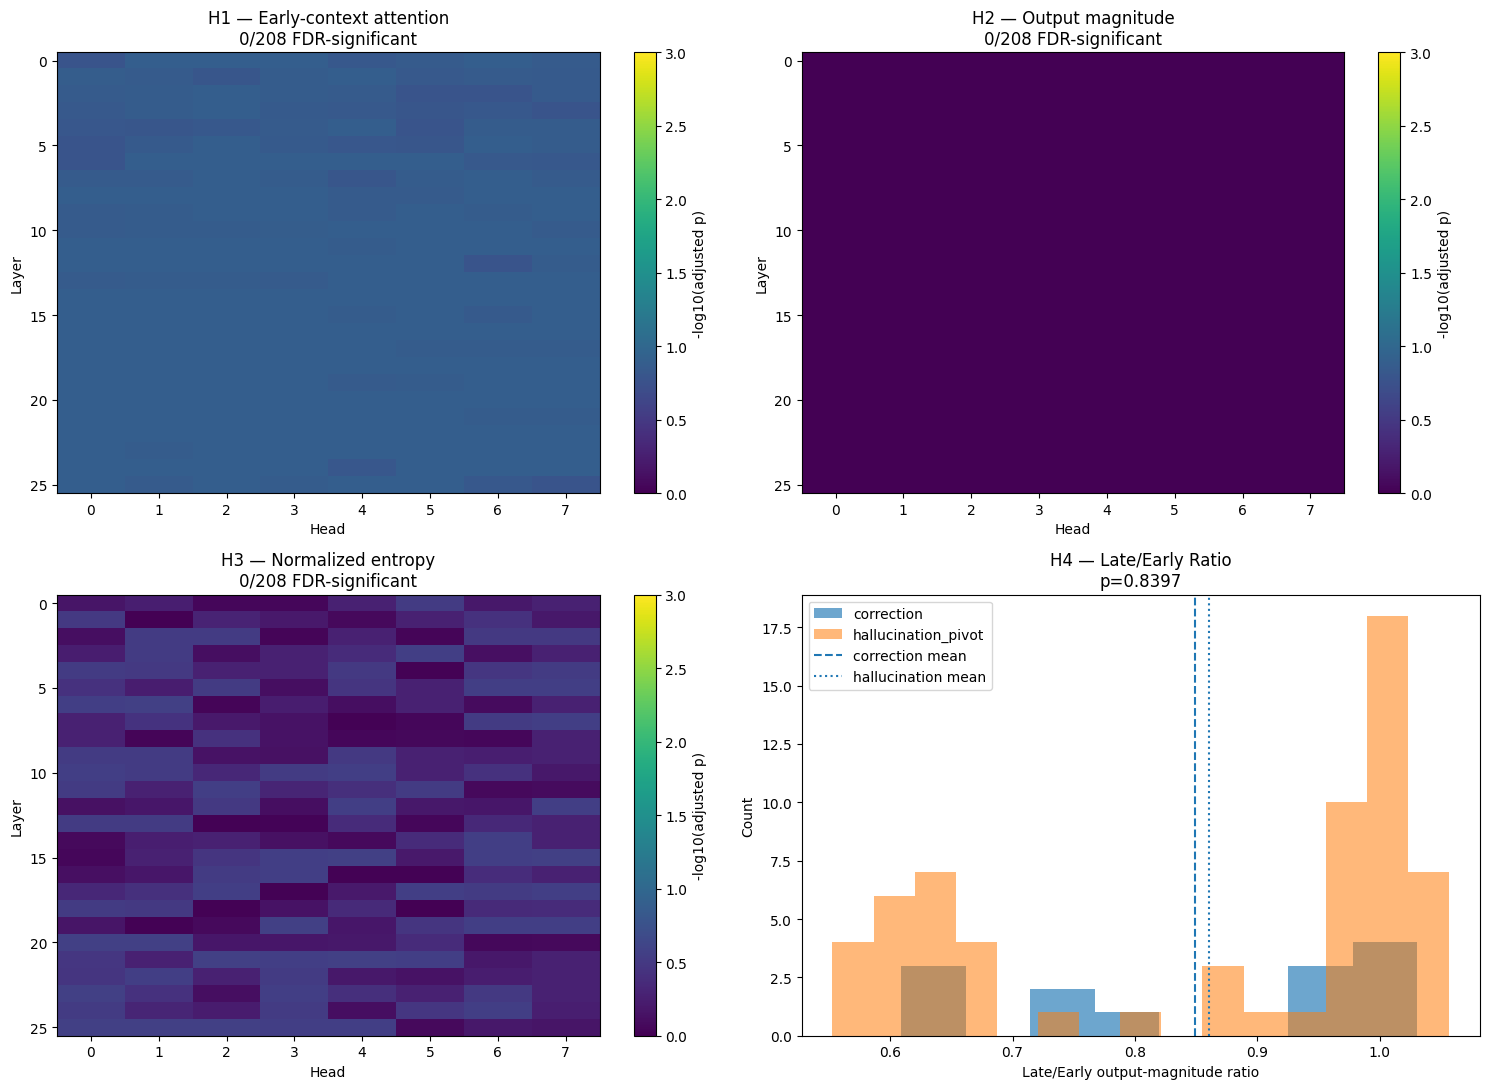

Saved: /kaggle/working/pivot_research_gemma/phase4_gemma_hypothesis_summary.png


In [9]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# H1
ax = axes[0, 0]
im = ax.imshow(
    -np.log10(adj_h1 + 1e-12),
    aspect="auto",
    origin="upper",
    vmin=0,
    vmax=3,
)
ax.set_title(
    f"H1 — Early-context attention\n"
    f"{reject_h1.sum()}/{N_LAYERS*N_HEADS} FDR-significant"
)
ax.set_xlabel("Head")
ax.set_ylabel("Layer")
fig.colorbar(im, ax=ax, label="-log10(adjusted p)")

# H2
ax = axes[0, 1]
im = ax.imshow(
    -np.log10(adj_h2 + 1e-12),
    aspect="auto",
    origin="upper",
    vmin=0,
    vmax=3,
)
ax.set_title(
    f"H2 — Output magnitude\n"
    f"{reject_h2.sum()}/{N_LAYERS*N_HEADS} FDR-significant"
)
ax.set_xlabel("Head")
ax.set_ylabel("Layer")
fig.colorbar(im, ax=ax, label="-log10(adjusted p)")

# H3
ax = axes[1, 0]
im = ax.imshow(
    -np.log10(adj_h3 + 1e-12),
    aspect="auto",
    origin="upper",
    vmin=0,
    vmax=3,
)
ax.set_title(
    f"H3 — Normalized entropy\n"
    f"{reject_h3.sum()}/{N_LAYERS*N_HEADS} FDR-significant"
)
ax.set_xlabel("Head")
ax.set_ylabel("Layer")
fig.colorbar(im, ax=ax, label="-log10(adjusted p)")

# H4
ax = axes[1, 1]
ax.hist(
    h4_features[corr_mask],
    bins=8,
    alpha=0.65,
    label="correction",
)
ax.hist(
    h4_features[halluc_mask],
    bins=15,
    alpha=0.55,
    label="hallucination_pivot",
)
ax.axvline(
    h4_features[corr_mask].mean(),
    linestyle="--",
    label="correction mean",
)
ax.axvline(
    h4_features[halluc_mask].mean(),
    linestyle=":",
    label="hallucination mean",
)
ax.set_title(f"H4 — Late/Early Ratio\np={p_h4:.4f}")
ax.set_xlabel("Late/Early output-magnitude ratio")
ax.set_ylabel("Count")
ax.legend()

plt.tight_layout()
plt.savefig(FIGURE_PATH, dpi=140, bbox_inches="tight")
plt.show()

print("Saved:", FIGURE_PATH)

## 10. Combined classifier

Gemma has:

- 208 H1 features
- 208 H2 features
- 208 H3 features
- 1 H4 feature

Total = **625 features**.

The classifier configuration is intentionally frozen to match Qwen:

- StandardScaler fitted inside each training fold
- L2 logistic regression
- `C=0.01`
- `class_weight="balanced"`
- 5-fold stratified CV

In [10]:
X = np.concatenate([
    h1_features.reshape(n_records, -1),
    h2_features.reshape(n_records, -1),
    h3_features.reshape(n_records, -1),
    h4_features.reshape(n_records, 1),
], axis=1)

expected_features = 3 * (N_LAYERS * N_HEADS) + 1

print("Feature matrix:", X.shape)
assert X.shape == (76, expected_features)
assert expected_features == 625

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)

instance_preds = np.zeros(n_records, dtype=int)
instance_probas = np.zeros(n_records, dtype=float)

instance_fold_results = []

for fold_idx, (tr, te) in enumerate(skf.split(X, y)):
    scaler = StandardScaler()

    Xtr = scaler.fit_transform(X[tr])
    Xte = scaler.transform(X[te])

    clf = LogisticRegression(
        class_weight="balanced",
        max_iter=3000,
        C=0.01,
        random_state=42,
    )

    clf.fit(Xtr, y[tr])

    preds = clf.predict(Xte)
    probas = clf.predict_proba(Xte)[:, 1]

    instance_preds[te] = preds
    instance_probas[te] = probas

    ba = balanced_accuracy_score(y[te], preds)
    auc = roc_auc_score(y[te], probas)

    instance_fold_results.append({
        "fold": fold_idx,
        "n_test": len(te),
        "n_correction": int(y[te].sum()),
        "balanced_accuracy": float(ba),
        "roc_auc": float(auc),
    })

    print(
        f"Fold {fold_idx}: "
        f"n={len(te)}, "
        f"correction={int(y[te].sum())}, "
        f"bal_acc={ba:.3f}, "
        f"AUC={auc:.3f}"
    )

instance_ba = balanced_accuracy_score(y, instance_preds)
instance_f1 = f1_score(y, instance_preds, zero_division=0)
instance_auc = roc_auc_score(y, instance_probas)

print("\nINSTANCE-LEVEL CV")
print(f"Balanced accuracy: {instance_ba:.3f}")
print(f"F1:                {instance_f1:.3f}")
print(f"ROC-AUC:           {instance_auc:.3f}")

Feature matrix: (76, 625)
Fold 0: n=16, correction=3, bal_acc=0.590, AUC=0.667
Fold 1: n=15, correction=2, bal_acc=0.346, AUC=0.346
Fold 2: n=15, correction=2, bal_acc=0.346, AUC=0.385
Fold 3: n=15, correction=3, bal_acc=0.333, AUC=0.167
Fold 4: n=15, correction=3, bal_acc=0.792, AUC=0.722

INSTANCE-LEVEL CV
Balanced accuracy: 0.503
F1:                0.222
ROC-AUC:           0.503


## 11. Prompt-grouped cross-validation

All generations from the same `prompt_id` remain in the same fold.

This is the more important Gemma classifier estimate because it asks whether the signal generalizes to **unseen prompts**, rather than unseen generations of prompts already represented in training.

In [11]:
unique_prompts = np.unique(prompt_ids)

print("Unique prompts:", len(unique_prompts))

sgkf = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)

group_preds = np.zeros(n_records, dtype=int)
group_probas = np.zeros(n_records, dtype=float)

group_fold_results = []

for fold_idx, (tr, te) in enumerate(
    sgkf.split(X, y, groups=prompt_ids)
):
    if len(np.unique(y[tr])) < 2:
        raise RuntimeError(
            f"Fold {fold_idx}: training split has only one class."
        )

    if len(np.unique(y[te])) < 2:
        print(
            f"WARNING: fold {fold_idx} test split has only one class; "
            "fold AUC will be undefined."
        )

    scaler = StandardScaler()

    Xtr = scaler.fit_transform(X[tr])
    Xte = scaler.transform(X[te])

    clf = LogisticRegression(
        class_weight="balanced",
        max_iter=3000,
        C=0.01,
        random_state=42,
    )

    clf.fit(Xtr, y[tr])

    preds = clf.predict(Xte)
    probas = clf.predict_proba(Xte)[:, 1]

    group_preds[te] = preds
    group_probas[te] = probas

    ba = balanced_accuracy_score(y[te], preds)

    fold_auc = (
        roc_auc_score(y[te], probas)
        if len(np.unique(y[te])) == 2
        else None
    )

    group_fold_results.append({
        "fold": fold_idx,
        "n_test": len(te),
        "n_prompts": int(len(np.unique(prompt_ids[te]))),
        "n_correction": int(y[te].sum()),
        "balanced_accuracy": float(ba),
        "roc_auc": None if fold_auc is None else float(fold_auc),
    })

    print(
        f"Fold {fold_idx}: "
        f"n={len(te)}, "
        f"prompts={len(np.unique(prompt_ids[te]))}, "
        f"correction={int(y[te].sum())}, "
        f"bal_acc={ba:.3f}, "
        f"AUC={'NA' if fold_auc is None else f'{fold_auc:.3f}'}"
    )

group_ba = balanced_accuracy_score(y, group_preds)
group_f1 = f1_score(y, group_preds, zero_division=0)
group_auc = roc_auc_score(y, group_probas)

print("\nPROMPT-GROUPED CV")
print(f"Balanced accuracy: {group_ba:.3f}")
print(f"F1:                {group_f1:.3f}")
print(f"ROC-AUC:           {group_auc:.3f}")

Unique prompts: 47
Fold 0: n=11, prompts=7, correction=2, bal_acc=0.583, AUC=0.667
Fold 1: n=15, prompts=11, correction=4, bal_acc=0.364, AUC=0.523
Fold 2: n=16, prompts=9, correction=2, bal_acc=0.500, AUC=0.643
Fold 3: n=16, prompts=10, correction=2, bal_acc=0.679, AUC=0.679
Fold 4: n=18, prompts=10, correction=3, bal_acc=0.733, AUC=0.689

PROMPT-GROUPED CV
Balanced accuracy: 0.549
F1:                0.278
ROC-AUC:           0.614


## 12. Cross-domain ablation

This mirrors the Qwen analysis but should be interpreted cautiously.

Gemma has only **1 logic correction**, so the held-out logic AUC is extremely unstable. The notebook reports class counts explicitly and does not treat these estimates as primary evidence.

In [12]:
cross_domain_results = {}

print("Cross-domain ablation:")

for held_out in ["math", "logic", "misdirection"]:
    test_mask = categories == held_out
    train_mask = ~test_mask

    y_train = y[train_mask]
    y_test = y[test_mask]

    print(
        f"\nHeld out: {held_out}"
        f"\n  train n={train_mask.sum()}, correction={int(y_train.sum())}"
        f"\n  test  n={test_mask.sum()}, correction={int(y_test.sum())}"
    )

    if len(np.unique(y_train)) < 2:
        print("  SKIPPED: training set has only one class.")
        cross_domain_results[held_out] = {
            "status": "skipped_one_class_train"
        }
        continue

    if len(np.unique(y_test)) < 2:
        print("  SKIPPED AUC: held-out set has only one class.")
        cross_domain_results[held_out] = {
            "status": "skipped_one_class_test",
            "n_test": int(test_mask.sum()),
            "n_correction_test": int(y_test.sum()),
        }
        continue

    scaler = StandardScaler()

    Xtr = scaler.fit_transform(X[train_mask])
    Xte = scaler.transform(X[test_mask])

    clf = LogisticRegression(
        class_weight="balanced",
        max_iter=3000,
        C=0.01,
        random_state=42,
    )

    clf.fit(Xtr, y_train)

    preds = clf.predict(Xte)
    probas = clf.predict_proba(Xte)[:, 1]

    ba = balanced_accuracy_score(y_test, preds)
    auc = roc_auc_score(y_test, probas)

    print(f"  balanced accuracy={ba:.3f}")
    print(f"  ROC-AUC={auc:.3f}")

    if int(y_test.sum()) < 3:
        print(
            "  WARNING: fewer than 3 corrections in held-out set; "
            "this AUC is highly unstable."
        )

    cross_domain_results[held_out] = {
        "status": "ok",
        "n_test": int(test_mask.sum()),
        "n_correction_test": int(y_test.sum()),
        "balanced_accuracy": float(ba),
        "roc_auc": float(auc),
    }

Cross-domain ablation:

Held out: math
  train n=41, correction=10
  test  n=35, correction=3
  balanced accuracy=0.484
  ROC-AUC=0.458

Held out: logic
  train n=67, correction=12
  test  n=9, correction=1
  balanced accuracy=0.312
  ROC-AUC=0.375

Held out: misdirection
  train n=44, correction=4
  test  n=32, correction=9
  balanced accuracy=0.370
  ROC-AUC=0.411


## 13. Save compact feature matrix

This makes later robustness analyses much cheaper. Phase 4b/4c-style analyses can operate on the 625-dimensional feature matrix without reloading the raw attention tensors.

In [13]:
np.savez_compressed(
    FEATURES_PATH,
    X=X.astype(np.float32),
    y=y.astype(np.int8),
    prompt_ids=prompt_ids,
    categories=categories,
    h1=h1_features.astype(np.float32),
    h2=h2_features.astype(np.float32),
    h3=h3_features.astype(np.float32),
    h4=h4_features.astype(np.float32),
    instance_oof_probas=instance_probas.astype(np.float32),
    grouped_oof_probas=group_probas.astype(np.float32),
)

print("Saved:", FEATURES_PATH)
print(f"Size: {os.path.getsize(FEATURES_PATH)/1e6:.2f} MB")

Saved: /kaggle/working/pivot_research_gemma/phase4_gemma_features.npz
Size: 0.34 MB


## 14. Save results

In [14]:
results = {
    "model": manifest["model_name"],
    "n_records": int(n_records),
    "n_corrections": int(corr_mask.sum()),
    "n_hallucination_pivots": int(halluc_mask.sum()),
    "n_layers": int(N_LAYERS),
    "n_heads": int(N_HEADS),
    "n_total_heads": int(N_LAYERS * N_HEADS),
    "n_features": int(X.shape[1]),

    "h1": {
        "n_sig_fdr": int(reject_h1.sum()),
        "best_raw_p": float(p_h1.min()),
        "best_adj_p": float(adj_h1.min()),
        "raw_p_below_05": int((p_h1 < 0.05).sum()),
    },

    "h2": {
        "n_sig_fdr": int(reject_h2.sum()),
        "best_raw_p": float(p_h2.min()),
        "best_adj_p": float(adj_h2.min()),
        "raw_p_below_05": int((p_h2 < 0.05).sum()),
    },

    "h3": {
        "n_sig_fdr": int(reject_h3.sum()),
        "best_raw_p": float(p_h3.min()),
        "best_adj_p": float(adj_h3.min()),
        "raw_p_below_05": int((p_h3 < 0.05).sum()),
        "raw_p_below_05_fraction": float((p_h3 < 0.05).mean()),
        "entropy_definition": "mask-defined normalized Shannon entropy",
    },

    "h4": {
        "p_value": float(p_h4),
        "difference_halluc_minus_correction": float(diff_h4),
        "correction_mean": float(h4_features[corr_mask].mean()),
        "hallucination_mean": float(h4_features[halluc_mask].mean()),
    },

    "classifier_instance_cv": {
        "balanced_accuracy": float(instance_ba),
        "f1": float(instance_f1),
        "roc_auc": float(instance_auc),
        "folds": instance_fold_results,
    },

    "classifier_prompt_grouped_cv": {
        "balanced_accuracy": float(group_ba),
        "f1": float(group_f1),
        "roc_auc": float(group_auc),
        "folds": group_fold_results,
    },

    "cross_domain": cross_domain_results,

    "class_counts_by_category": {
        cat: {
            "n": int((categories == cat).sum()),
            "corrections": int(y[categories == cat].sum()),
            "hallucination_pivots": int(
                (categories == cat).sum()
                - y[categories == cat].sum()
            ),
        }
        for cat in sorted(np.unique(categories))
    },
}

with open(RESULTS_PATH, "w", encoding="utf-8") as f:
    json.dump(results, f, indent=2)

print("Saved results:")
print(RESULTS_PATH)

Saved results:
/kaggle/working/pivot_research_gemma/phase4_gemma_results.json


## 15. Final console summary

These are the numbers to copy back for review before changing the paper.

In [15]:
print("=" * 72)
print("GEMMA PHASE 4 SUMMARY")
print("=" * 72)

print(f"n={n_records} ({corr_mask.sum()} correction / {halluc_mask.sum()} hallucination_pivot)")
print(f"Heads tested: {N_LAYERS*N_HEADS}")
print(f"Features: {X.shape[1]}")

print("\nHEAD-WISE TESTS")
print(
    f"H1: {reject_h1.sum()} FDR-significant | "
    f"best raw={p_h1.min():.4f} | best adj={adj_h1.min():.4f}"
)
print(
    f"H2: {reject_h2.sum()} FDR-significant | "
    f"best raw={p_h2.min():.4f} | best adj={adj_h2.min():.4f}"
)
print(
    f"H3: {reject_h3.sum()} FDR-significant | "
    f"best raw={p_h3.min():.4f} | best adj={adj_h3.min():.4f} | "
    f"raw p<.05={(p_h3 < 0.05).mean():.1%}"
)
print(f"H4: diff={diff_h4:+.4f} | p={p_h4:.4f}")

print("\nCLASSIFIER")
print(
    f"Instance-level CV: "
    f"BA={instance_ba:.3f} | F1={instance_f1:.3f} | AUC={instance_auc:.3f}"
)
print(
    f"Prompt-grouped CV: "
    f"BA={group_ba:.3f} | F1={group_f1:.3f} | AUC={group_auc:.3f}"
)

print("\nCROSS-DOMAIN")
for domain, r in cross_domain_results.items():
    if r.get("status") == "ok":
        flag = " [VERY LOW POSITIVE COUNT]" if r["n_correction_test"] < 3 else ""
        print(
            f"{domain:<14} "
            f"n={r['n_test']:<3} "
            f"corr={r['n_correction_test']:<2} "
            f"BA={r['balanced_accuracy']:.3f} "
            f"AUC={r['roc_auc']:.3f}"
            f"{flag}"
        )
    else:
        print(domain, r)

print("\nFiles:")
print(" ", RESULTS_PATH)
print(" ", FEATURES_PATH)
print(" ", FIGURE_PATH)

GEMMA PHASE 4 SUMMARY
n=76 (13 correction / 63 hallucination_pivot)
Heads tested: 208
Features: 625

HEAD-WISE TESTS
H1: 0 FDR-significant | best raw=0.0126 | best adj=0.1277
H2: 0 FDR-significant | best raw=0.0166 | best adj=0.9757
H3: 0 FDR-significant | best raw=0.0026 | best adj=0.2738 | raw p<.05=16.8%
H4: diff=+0.0112 | p=0.8397

CLASSIFIER
Instance-level CV: BA=0.503 | F1=0.222 | AUC=0.503
Prompt-grouped CV: BA=0.549 | F1=0.278 | AUC=0.614

CROSS-DOMAIN
math           n=35  corr=3  BA=0.484 AUC=0.458
logic          n=9   corr=1  BA=0.312 AUC=0.375 [VERY LOW POSITIVE COUNT]
misdirection   n=32  corr=9  BA=0.370 AUC=0.411

Files:
  /kaggle/working/pivot_research_gemma/phase4_gemma_results.json
  /kaggle/working/pivot_research_gemma/phase4_gemma_features.npz
  /kaggle/working/pivot_research_gemma/phase4_gemma_hypothesis_summary.png
